# 🏆 05 · Evaluate, quality gate & Model Registry
### Evaluar, control de calidad y Registro de Modelos

| | |
|---|---|
| 🍳 **Analogy / Analogía** | *The jury tastes every dish; only the best one goes on the menu* · *El jurado prueba los platos; solo el mejor entra al menú* |
| 🎯 **Goal / Objetivo** | Pick a champion only if it's truly better than guessing · Elegir un campeón solo si es mejor que adivinar |
| 🏭 **Becomes / Se convierte en** | `src/models/promote.py` + `src/models/check_gate.py` |

```
 candidates ──▶ leaderboard ──▶ 🚦 QUALITY GATE ──✅──▶ Model Registry  gold-direction-h1  v1 @champion
                                        │                                         │
                                        └──❌──▶ nothing changes                  └──▶ models/champion/ → API
```

> **EN:** This notebook reads the **official pipeline** results (run `dvc repro` first).
> **ES:** Este notebook lee los resultados del **pipeline oficial** (ejecuta `dvc repro` antes).

In [1]:
import os
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)

import json

import matplotlib.pyplot as plt
import mlflow
import pandas as pd
from mlflow import MlflowClient

plt.rcParams["figure.figsize"] = (11, 4)
mlflow.set_tracking_uri(f"sqlite:///{(ROOT / 'mlflow.db').as_posix()}")

runs = mlflow.search_runs(experiment_names=["gold-direction-h1"],
                          filter_string="tags.model_type != ''", order_by=["start_time DESC"])
latest = runs.drop_duplicates("tags.model_type")  # most recent run of each model
cols = ["tags.model_type", "metrics.test_roc_auc", "metrics.test_accuracy", "metrics.cv_roc_auc_mean",
        "metrics.test_strategy_return", "metrics.test_buyhold_return"]
board = latest[cols].set_index("tags.model_type").sort_values("metrics.test_roc_auc", ascending=False)
board.columns = [c.replace("metrics.", "") for c in board.columns]
board.round(4)

2026/09/28 22:24:40 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/09/28 22:24:40 INFO mlflow.store.db.utils: Updating database tables


INFO  [alembic.runtime.migration] Context impl SQLiteImpl.


INFO  [alembic.runtime.migration] Will assume non-transactional DDL.


INFO  [alembic.runtime.migration] Context impl SQLiteImpl.


INFO  [alembic.runtime.migration] Will assume non-transactional DDL.


,test_roc_auc,test_accuracy,cv_roc_auc_mean,test_strategy_return,test_buyhold_return
tags.model_type,,,,,
xgboost,0.5140,0.5148,0.5092,0.0527,0.0982
random_forest,0.5032,0.5045,0.5119,-0.1991,0.0982
logistic_regression,0.5028,0.5045,0.5079,-0.1739,0.0982
baseline,0.5000,0.5092,0.5000,0.0982,0.0982


## 1️⃣ Leaderboard / Tabla de posiciones

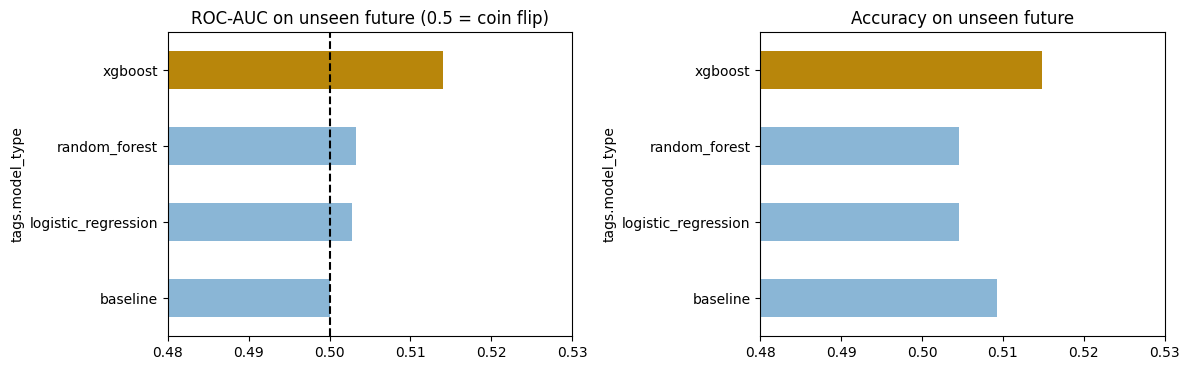

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
colors = ["#b8860b" if i == 0 else "#8ab6d6" for i in range(len(board))]
board["test_roc_auc"].plot.barh(ax=axes[0], color=colors).invert_yaxis()
axes[0].axvline(0.5, color="black", ls="--")
axes[0].set_xlim(0.48, max(0.53, board.test_roc_auc.max() + 0.005))
axes[0].set_title("ROC-AUC on unseen future (0.5 = coin flip)")
board["test_accuracy"].plot.barh(ax=axes[1], color=colors).invert_yaxis()
axes[1].set_xlim(0.48, 0.53)
axes[1].set_title("Accuracy on unseen future")
plt.tight_layout()
plt.show()

### 📏 Metrics in plain words / Métricas en palabras simples
| Metric | EN | ES |
|---|---|---|
| **Accuracy** | % of hours where UP/DOWN was right | % de horas en que acertó SUBE/BAJA |
| **Precision** | When it says UP, how often is it really UP? | Cuando dice SUBE, ¿cuántas veces sube de verdad? |
| **Recall** | Of all real UPs, how many did it catch? | De todas las subidas reales, ¿cuántas detectó? |
| **ROC-AUC** | Can it rank "more likely UP" above "less likely"? 0.5 = coin | ¿Ordena bien lo "más probable que suba"? 0.5 = moneda |

## 2️⃣ Look inside the champion's run / Mirar dentro de la ejecución del campeón

C:\Users\Asus\Desktop\Claude Projects\MLOps Trading\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


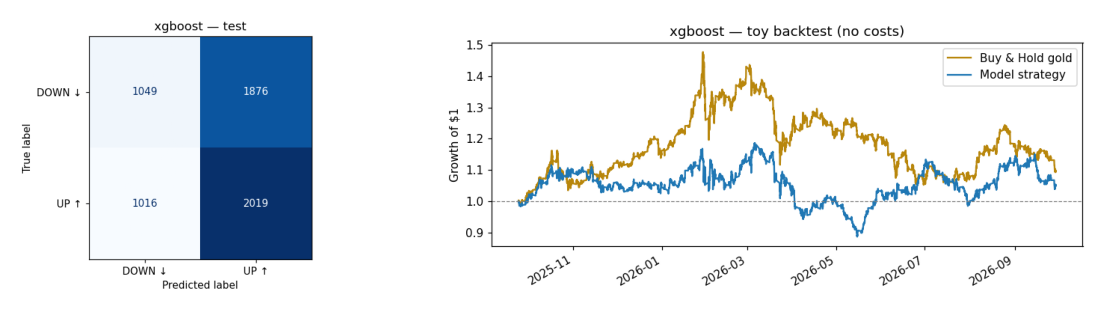

In [3]:
metrics = json.loads(Path("reports/metrics.json").read_text())
champion_run = metrics["run_id"]
local = mlflow.artifacts.download_artifacts(f"runs:/{champion_run}/plots")
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [1, 2]})
for ax, img in zip(axes, ["confusion_matrix.png", "equity_curve.png"], strict=True):
    ax.imshow(plt.imread(Path(local) / img))
    ax.axis("off")
plt.show()

**EN — The honest truth:** the model beats the coin flip *slightly*, but the toy strategy earns **less than
simply holding gold** during a strong bull market. Beating 50% ≠ making money (and we ignore spreads/fees!).
The point of this project is the **MLOps process**, not a money machine.

**ES — La verdad honesta:** el modelo le gana *un poco* a la moneda, pero la estrategia de juguete gana **menos
que simplemente mantener oro** en un mercado muy alcista. Superar el 50% ≠ ganar dinero (¡y sin comisiones!).
El objetivo del proyecto es el **proceso MLOps**, no una máquina de dinero.

## 3️⃣ 🚦 The quality gate / El control de calidad

In [4]:
for check, ok in metrics["gate_checks"].items():
    print("✅" if ok else "❌", check)
print("\nGate passed → promote!" if metrics["gate_passed"] else "\nGate failed → keep old champion")

✅ roc_auc >= 0.51
✅ beats baseline (roc_auc)
✅ beats baseline (accuracy)

Gate passed → promote!


## 4️⃣ The Model Registry / El Registro de Modelos
**EN:** Like a library catalog: every approved model gets a **version number**, and an **alias**
(`@champion`) points to the one in production. Rolling back = moving the alias to an older version.

**ES:** Como el catálogo de una biblioteca: cada modelo aprobado recibe un **número de versión**, y un **alias**
(`@champion`) apunta al que está en producción. Volver atrás = mover el alias a una versión anterior.

In [5]:
client = MlflowClient()
for mv in client.search_model_versions("name='gold-direction-h1'"):
    print(f"v{mv.version:<3} run={mv.run_id[:8]}  aliases={mv.aliases}  type={mv.tags.get('model_type')}")

2026/09/28 22:24:46 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/09/28 22:24:46 INFO mlflow.store.db.utils: Updating database tables


INFO  [alembic.runtime.migration] Context impl SQLiteImpl.


INFO  [alembic.runtime.migration] Will assume non-transactional DDL.


v1   run=6428e90d  aliases=[]  type=xgboost


In [6]:
# Load the production model BY NAME — no file paths needed / Cargar el modelo de producción POR NOMBRE
champion = mlflow.sklearn.load_model("models:/gold-direction-h1@champion")
df = pd.read_csv("data/processed/features.csv", parse_dates=["time"]) if Path("data/processed/features.csv").exists() \
    else pd.read_csv("data/processed/features_sample.csv", parse_dates=["time"])
features = [c for c in df.columns if c not in ("time", "close", "target")]
last = df.tail(5)
pd.DataFrame({"time": last.time, "close": last.close,
              "prob_UP": champion.predict_proba(last[features])[:, 1].round(3),
              "real_answer": last.target.map({1: "UP", 0: "DOWN"})})

,time,close,prob_UP,real_answer
29794,2026-09-28 23:00:00,4114.67,0.742,UP
29795,2026-09-29 01:00:00,4121.28,0.655,UP
29796,2026-09-29 02:00:00,4127.13,0.568,DOWN
29797,2026-09-29 03:00:00,4117.59,0.594,UP
29798,2026-09-29 04:00:00,4135.03,0.493,UP


---
## 🔁 From notebook to production / Del notebook a producción

| Notebook | Production |
|---|---|
| We compare the bars by eye | `promote.py` ranks by `params.yaml → evaluate.primary_metric` |
| We decide "looks good" | `gate()` applies **written rules** (min AUC, beat baseline) — no opinions |
| Manual `register_model` | Automatic registration + `@champion` alias + export to `models/champion/` |
| — | **CI** runs `check_gate.py` on every push: a worse champion can't be merged |